/var/folders/yy/z6qg2k8n2h3g714cbbr9xp040000gn/T/ipykernel_69766/2514025121.py:136: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


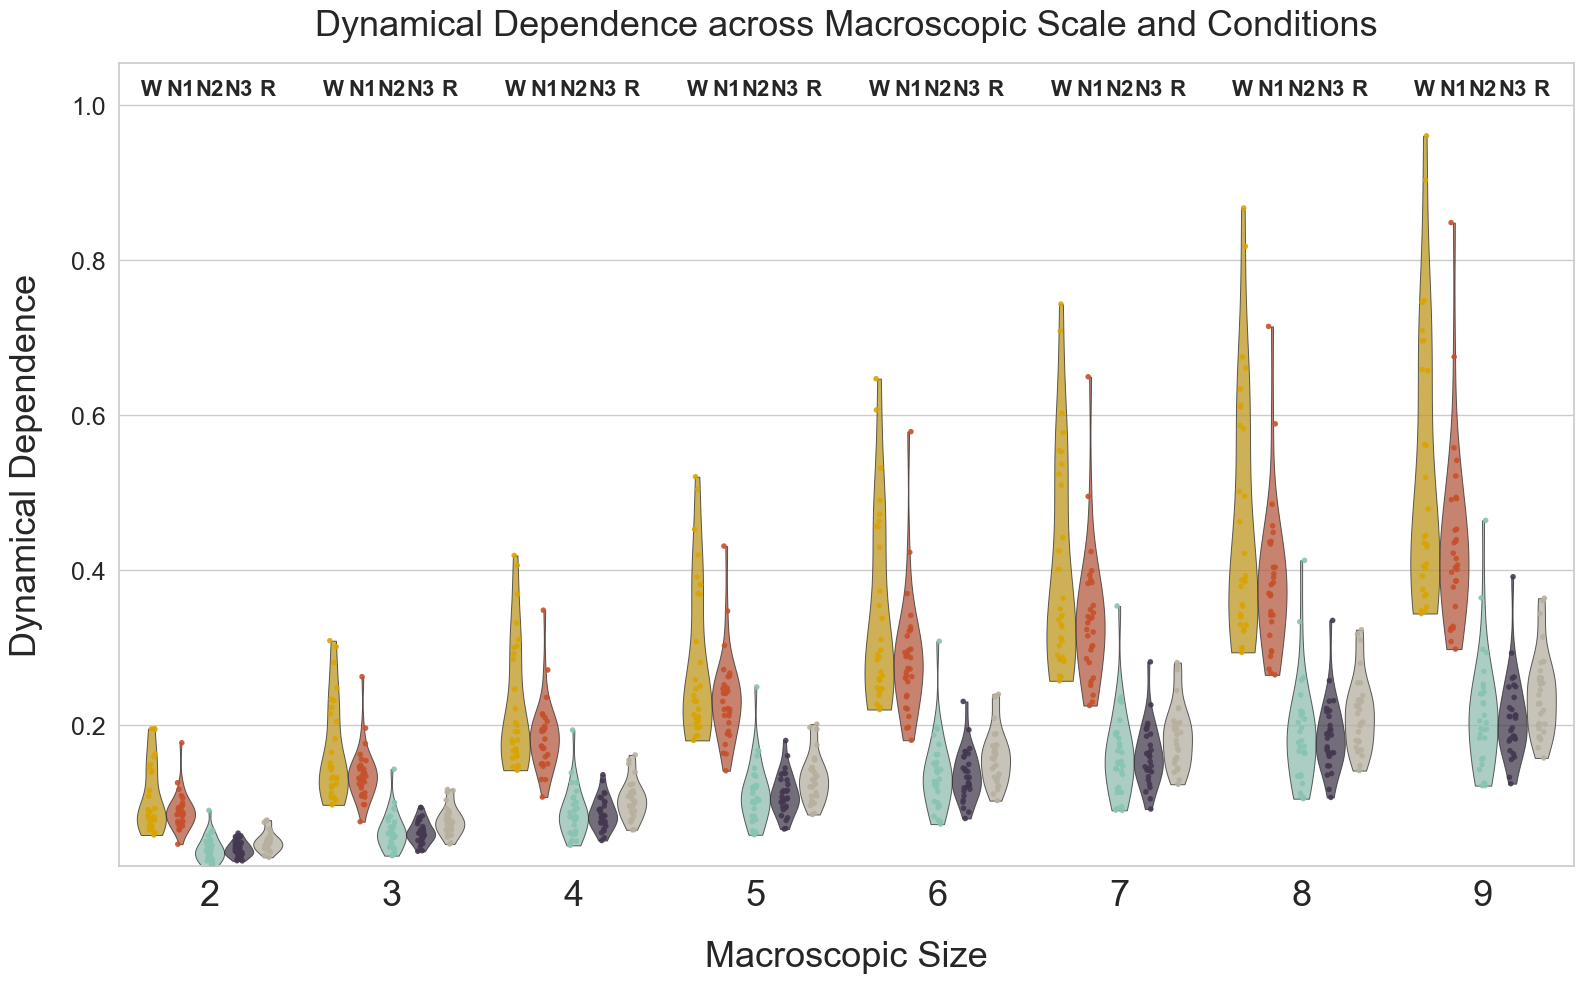

In [58]:
import os
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# Step 1: Setup and Imports
# ----------------------------

# Set the directory containing the .mat files
data_dir = '/Users/borjan/code/healthy-sleep-project/code/results/ssdi_results/time'

# Define participants
participants = [f"{i:02d}" for i in range(1, 30)]  # Participants 01 to 29

# Define conditions with the desired order
conditions = ['W', 'N1', 'N2', 'N3', 'R']

# Macroscopic sizes as strings for categorical plotting
macros = [str(m) for m in range(2, 10)]  # '2' to '9'

# Darjeeling2 color palette
# palette = {
#     'W': '#E7D8C9',    # Light beige
#     'N1': '#276678',   # Blue
#     'N2': '#C49553',   # Gold/Bronze
#     'N3': '#A8D0DB',   # Pale Aqua
#     'R': '#000000'     # Black
# }

# different pallette
# palette = {
#     'W': '#665C2C',    # Olive green
#     'N1': '#E3C5A2',   # Light beige
#     'N2': '#E8B5A4',   # Pale coral
#     'N3': '#F3DBA2',   # Light yellow
#     'R': '#8BA39E'     # Muted green
# }

# Third option my favourite:
# New color palette inspired by the uploaded image
palette = {
    'W': '#D9A404',    # Golden yellow
    'N1': '#C7502C',   # Burnt orange
    'N2': '#89C4B3',   # Soft aqua
    'N3': '#443850',   # Deep purple
    'R': '#B8B09F'     # Muted beige/grey
}

# Initialize a list to collect all data
data_records = []

# ----------------------------
# Step 2: Data Extraction
# ----------------------------

for filename in os.listdir(data_dir):
    if filename.endswith('_ssdi_time_domain_results.mat'):
        filepath = os.path.join(data_dir, filename)
        
        # Extract subject ID and condition from filename
        # Filename pattern: EPCTL03_{condition}_ssdi_time_domain_results.mat
        parts = filename.split('_')
        if len(parts) < 4:
            print(f"Filename {filename} does not match the expected pattern. Skipping.")
            continue
        subject_part = parts[0]  # e.g., 'EPCTL03'
        condition = parts[1]     # e.g., 'W', 'N1', etc.
        subject_id = subject_part[-2:]  # Last two characters, e.g., '03'

        # Check if the subject and condition are in our lists
        if subject_id not in participants:
            print(f"Subject {subject_id} not in participant list. Skipping.")
            continue
        if condition not in conditions:
            print(f"Condition {condition} not in condition list. Skipping.")
            continue

        # Load the .mat file
        try:
            mat_data = scipy.io.loadmat(filepath, simplify_cells=True)
        except Exception as e:
            print(f"Error loading {filename}: {e}")
            continue

        # Get 'results' from mat_data
        if 'results' not in mat_data:
            print(f"No 'results' found in {filename}. Skipping.")
            continue
        results = mat_data['results']

        # For each macroscopic size m
        for m in range(2, 10):
            dopto_key = f'dopto_m{m}'

            # Check if the key exists in results
            if dopto_key in results:
                dopto_matrix = results[dopto_key]
                # Extract the minimal (most optimal) value
                dopto_values = dopto_matrix.flatten()
                if len(dopto_values) > 0:
                    minimal_value = dopto_values[0]  # First value is minimal
                    # Add a record to data_records
                    data_records.append({
                        'Subject': subject_id,
                        'Condition': condition,
                        'Macro': str(m),
                        'Dopto_Value': minimal_value
                    })
                else:
                    print(f"No values found in {dopto_key} for {filename}")
            else:
                print(f"{dopto_key} not found in results for {filename}")

# ----------------------------
# Step 3: Create DataFrame
# ----------------------------

df = pd.DataFrame(data_records)

# Ensure 'Condition' and 'Macro' are categorical variables with the specified order
df['Condition'] = pd.Categorical(df['Condition'], categories=conditions, ordered=True)
df['Macro'] = pd.Categorical(df['Macro'], categories=macros, ordered=True)

# ----------------------------
# Step 4: Plotting
# ----------------------------

sns.set(style="whitegrid")

plt.figure(figsize=(16, 10))

# Create the violin plot with conditions in the specified order
ax = sns.violinplot(
    x='Macro',
    y='Dopto_Value',
    hue='Condition',
    data=df,
    palette=palette,
    inner=None,        # Remove the inner quartile lines
    cut=0,
    scale='width',
    dodge=True,
    order=macros,
    hue_order=conditions,
    alpha=0.75,
    linewidth=0.7
)

# Overlay the data points corresponding to each violin plot
sns.stripplot(
    x='Macro',
    y='Dopto_Value',
    hue='Condition',
    data=df,
    palette=palette,
    dodge=True,
    jitter=True,
    size=4,
    order=macros,
    hue_order=conditions,
    alpha=0.9,
    legend=False
)

# Remove the legend as per your request
if ax.get_legend() is not None:
    ax.get_legend().remove()

# Add condition labels above each violin plot
n_conditions = len(conditions)
n_macros = len(macros)

# Calculate the shifts for each condition
dodge_amount = 0.8 / n_conditions  # Total dodge amount divided by number of conditions
offsets = np.linspace(-0.4 + dodge_amount / 2, 0.4 - dodge_amount / 2, n_conditions)

# Get the maximum y-value to position the labels
y_max = df['Dopto_Value'].max()
y_min = df['Dopto_Value'].min()
y_range = y_max - y_min
label_y = y_max + 0.05 * y_range  # Position labels 5% above the maximum y

# Add condition labels
for i, macro in enumerate(macros):
    for j, condition in enumerate(conditions):
        x_pos = i + offsets[j]
        ax.text(x_pos, label_y, condition, ha='center', va='bottom', fontsize=16, fontweight='bold')

# Adjust y-axis limits to accommodate the labels
ax.set_ylim(y_min, y_max + 0.1 * y_range)

# Set titles and labels
plt.title('Dynamical Dependence across Macroscopic Scale and Conditions', fontsize=26, pad=20)
plt.xticks(fontsize=26)
plt.xlabel('Macroscopic Size', fontsize=26, labelpad=20)
plt.yticks(fontsize=18)
plt.ylabel('Dynamical Dependence', fontsize=26, labelpad=20)

plt.tight_layout()

# Save the plot
plt.savefig('dynamical_dependence_plot.png', dpi=300, bbox_inches='tight')  # Added line to save the figure

# Show the plot
plt.show()


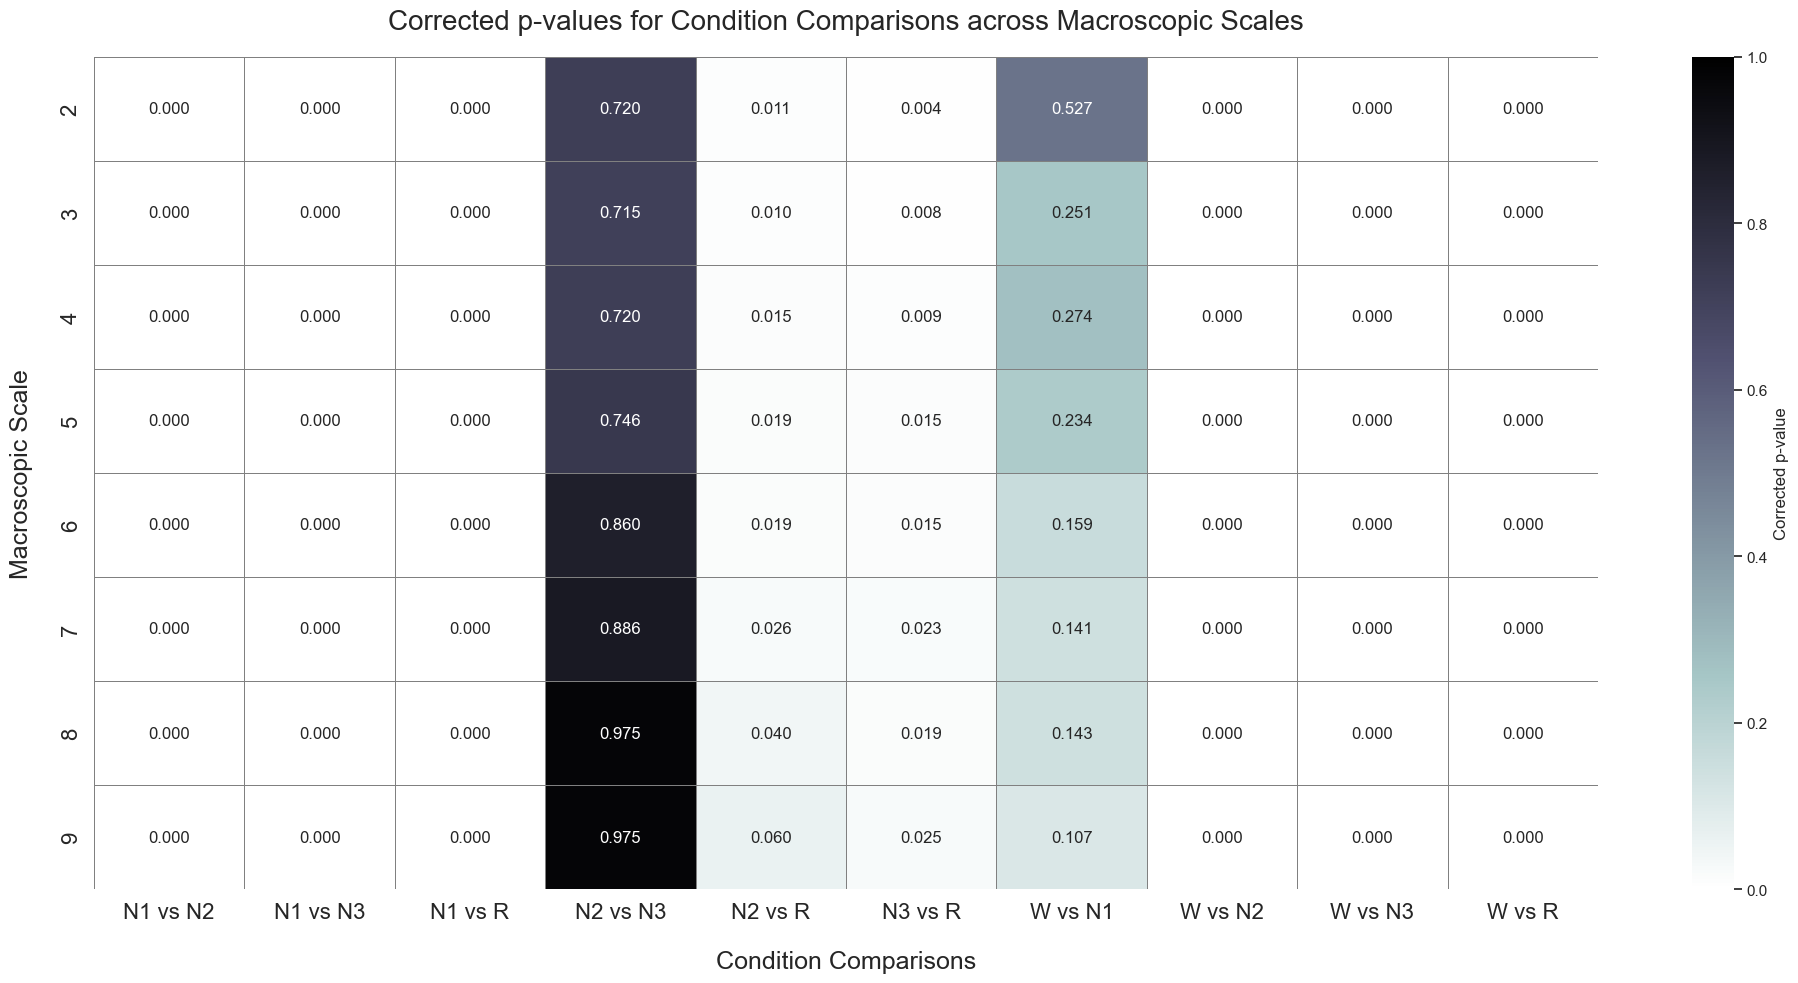


Corrected p-values after FDR correction:
Macro Size 2, Comparison W vs N1: Corrected p-value = 5.2710e-01
Macro Size 2, Comparison W vs N2: Corrected p-value = 1.4118e-09
Macro Size 2, Comparison W vs N3: Corrected p-value = 7.2694e-10
Macro Size 2, Comparison W vs R: Corrected p-value = 2.1292e-09
Macro Size 2, Comparison N1 vs N2: Corrected p-value = 1.6339e-09
Macro Size 2, Comparison N1 vs N3: Corrected p-value = 7.2694e-10
Macro Size 2, Comparison N1 vs R: Corrected p-value = 6.9046e-09
Macro Size 2, Comparison N2 vs N3: Corrected p-value = 7.1954e-01
Macro Size 2, Comparison N2 vs R: Corrected p-value = 1.0773e-02
Macro Size 2, Comparison N3 vs R: Corrected p-value = 4.1687e-03
Macro Size 3, Comparison W vs N1: Corrected p-value = 2.5056e-01
Macro Size 3, Comparison W vs N2: Corrected p-value = 9.8575e-10
Macro Size 3, Comparison W vs N3: Corrected p-value = 7.2694e-10
Macro Size 3, Comparison W vs R: Corrected p-value = 1.3669e-09
Macro Size 3, Comparison N1 vs N2: Corrected p-

In [49]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# ----------------------------
# Step 4: Statistical Analysis
# ----------------------------

# Get all possible pairs of conditions
condition_pairs = list(combinations(conditions, 2))

# Initialize list to collect p-values
p_value_records = []

for macro in macros:
    for cond1, cond2 in condition_pairs:
        # Get the data for cond1 and macro
        group1 = df[(df['Condition'] == cond1) & (df['Macro'] == macro)]['Dopto_Value'].values
        group2 = df[(df['Condition'] == cond2) & (df['Macro'] == macro)]['Dopto_Value'].values

        # Perform MWU test if both groups have data
        if len(group1) > 0 and len(group2) > 0:
            try:
                _, p_value = mannwhitneyu(group1, group2, alternative='two-sided')
            except ValueError as e:
                print(f"Could not perform MWU test for Macro {macro}, {cond1} vs {cond2}: {e}")
                p_value = np.nan
        else:
            print(f"Insufficient data for Macro {macro}, {cond1} vs {cond2}. Skipping MWU test.")
            p_value = np.nan

        # Store the record
        p_value_records.append({
            'Macro': macro,
            'Comparison': f"{cond1} vs {cond2}",
            'Cond1': cond1,
            'Cond2': cond2,
            'p_value': p_value
        })

# Collect all valid p-values
p_values_list = [record['p_value'] for record in p_value_records if not np.isnan(record['p_value'])]

# Apply FDR correction
if p_values_list:
    _, p_values_corrected, _, _ = multipletests(p_values_list, method='fdr_bh')

    # Map corrected p-values back
    corrected_index = 0
    for i, record in enumerate(p_value_records):
        if not np.isnan(record['p_value']):
            record['p_value_corrected'] = p_values_corrected[corrected_index]
            corrected_index += 1
        else:
            record['p_value_corrected'] = np.nan
else:
    print("No valid p-values to correct.")
    for record in p_value_records:
        record['p_value_corrected'] = np.nan

# Create DataFrame for p-values
p_values_df = pd.DataFrame(p_value_records)

# ----------------------------
# 5.2: Significance Matrix (Heatmap)
# ----------------------------

import matplotlib.pyplot as plt
import seaborn as sns

# Pivot the p_values_df to create a matrix suitable for heatmap
# Rows: Macroscopic Sizes, Columns: Condition Comparisons
heatmap_data = p_values_df.pivot(index='Macro', columns='Comparison', values='p_value_corrected')

# Sort the macros and comparisons for better visualization
heatmap_data = heatmap_data.reindex(sorted(heatmap_data.index))
heatmap_data = heatmap_data[sorted(heatmap_data.columns)]

plt.figure(figsize=(20, 10))

# Define a custom colormap
cmap = sns.color_palette("bone_r", as_cmap=True)

# Create the heatmap
ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap=cmap,
    linewidths=.5,
    linecolor='gray',
    cbar_kws={'label': 'Corrected p-value'},
    vmin=0,
    vmax=1
)

# Increase the x and y tick labels font size to 16
ax.set_xticklabels(ax.get_xticklabels(), fontsize=16)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=16)

plt.title('Corrected p-values for Condition Comparisons across Macroscopic Scales', fontsize=20, pad=20)
plt.xlabel('Condition Comparisons', fontsize=18, labelpad=20)
plt.ylabel('Macroscopic Scale', fontsize=18, labelpad=20)

plt.tight_layout()

# Save the heatmap
plt.savefig('dopto_significance_matrix.png', dpi=300, bbox_inches='tight')

# Show the heatmap
plt.show()

# ----------------------------
# Step 6: Display Statistical Results
# ----------------------------

# Print the corrected p-values
print("\nCorrected p-values after FDR correction:")
for idx, row in p_values_df.iterrows():
    macro = row['Macro']
    comparison = row['Comparison']
    p_val_corr = row['p_value_corrected']
    if not np.isnan(p_val_corr):
        print(f"Macro Size {macro}, Comparison {comparison}: Corrected p-value = {p_val_corr:.4e}")
    else:
        print(f"Macro Size {macro}, Comparison {comparison}: Insufficient data for statistical test.")


In [ ]:
# Import necessary libraries
import os
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ----------------------------
# Step 1: Data Loading and Organization
# ----------------------------

# Set the directory containing the .mat files
data_dir = '/Users/borjan/code/healthy-sleep-project/code/results/ssdi_results/time'

# Define conditions and macroscopic variables
conditions = ['W_', 'N1', 'N2', 'N3', 'R_']
macroscopic_vars = [f'm{num}' for num in range(2, 10)]  # m2 to m9

# Get list of participant files
participant_files = [f for f in os.listdir(data_dir) if f.endswith('.mat')]

# Extract participant IDs from filenames
participants = set()
for filename in participant_files:
    parts = filename.split('_')
    if len(parts) >= 3:
        participant_id = parts[0]  # 'EPCTL01' to 'EPCTL29'
        participants.add(participant_id)
participants = sorted(list(participants))
num_participants = len(participants)

# Prepare directory to save figures
results_dir = 'composite_figures_time_domain'
os.makedirs(results_dir, exist_ok=True)

# ----------------------------
# Step 2: Plotting Matrices
# ----------------------------

# Loop over conditions
for condition in conditions:
    print(f"Processing condition: {condition}")

    # Create a figure with 8 rows and num_participants columns
    fig, axes = plt.subplots(nrows=8, ncols=num_participants, figsize=(num_participants * 1.5, 8 * 1.5))

    # Ensure axes is a 2D array
    if num_participants == 1:
        axes = np.array([axes]).T  # Convert to 2D array with shape (8, 1)
    elif axes.ndim == 1:
        axes = axes.reshape(8, num_participants)

    # Loop over macroscopic variables (rows)
    for row_idx, m_var in enumerate(macroscopic_vars):
        # Loop over participants (columns)
        for col_idx, participant in enumerate(participants):
            # Build the filename for the participant and condition
            participant_file = f"{participant}_{condition}_ssdi_time_domain_results.mat"
            filepath = os.path.join(data_dir, participant_file)
            if not os.path.exists(filepath):
                print(f"File not found: {filepath}")
                continue

            # Load the .mat file
            try:
                mat_data = scipy.io.loadmat(filepath, simplify_cells=True)
            except Exception as e:
                print(f"Error loading file {filepath}: {e}")
                continue

            # Access the 'results' structure
            if 'results' in mat_data:
                results = mat_data['results']
            else:
                print(f"'results' structure not found in {filepath}")
                continue

            # Extract the matrix for the given macroscopic variable
            data_key = f"gopto_{m_var}"
            if data_key in results:
                matrix = results[data_key]
                # Invert the matrix along the y-axis (flip the rows) if needed
                matrix_flipped = np.flipud(matrix)
            else:
                print(f"Data key {data_key} not found in results of {filepath}")
                continue

            # Plot the flipped matrix in the appropriate subplot
            ax = axes[row_idx, col_idx]
            im = ax.imshow(matrix_flipped, aspect='auto', interpolation='none', cmap='bone_r')
            ax.axis('off')  # Remove axis labels, ticks, etc.

    # Remove any unused axes
    for idx in range(len(macroscopic_vars) * num_participants, axes.size):
        fig.delaxes(axes.flat[idx])

    # Adjust spacing and save the figure
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout(pad=0)
    # Save the figure with condition in the filename
    condition_filename = os.path.join(results_dir, f'{condition}_gopto_matrices.png')
    plt.savefig(condition_filename, dpi=300, bbox_inches='tight', pad_inches=0)
    plt.close(fig)

print("All condition composite figures have been generated and saved.")



Processing condition: W_
Processing condition: N1
Processing condition: N2
Processing condition: N3
Processing condition: R_
All condition composite figures have been generated and saved.
Creating a composite figure of all conditions.
Composite figure of all conditions has been generated and saved.


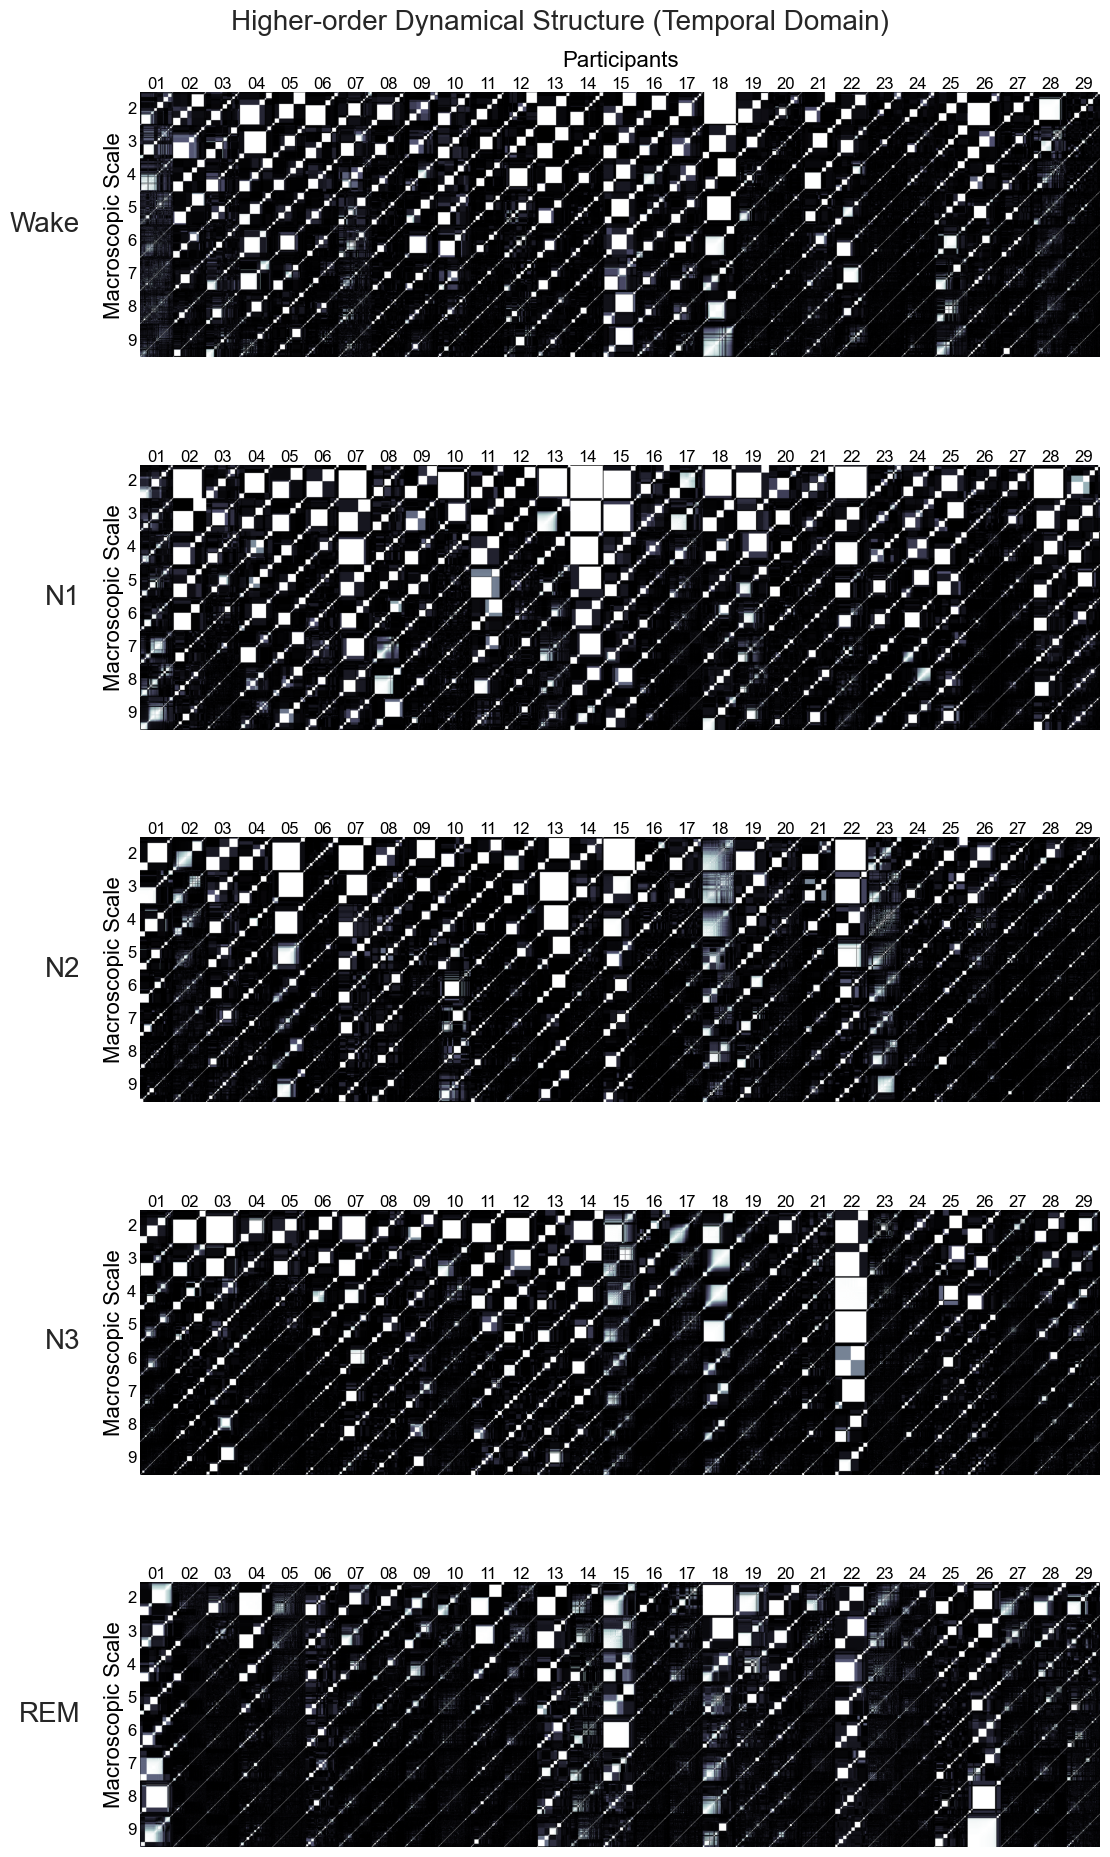

Ultimate composite figure for the temporal domain has been generated and saved.


In [84]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Define conditions
conditions = ['W_', 'N1', 'N2', 'N3', 'R_']  # Conditions used in filenames

# Mapping of condition codes to labels for plots
condition_labels = {
    'W_': 'Wake',
    'N1': 'N1',
    'N2': 'N2',
    'N3': 'N3',
    'R_': 'REM'
}

# Prepare directory where composite figures are saved
results_dir = 'composite_figures_time_domain'  # Adjusted directory name

# Create a figure with 5 rows and 1 column
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(12, 20))  # Adjusted figure size

# Adjust subplots to reduce whitespace
plt.subplots_adjust(left=0.15, right=0.95, top=0.95, bottom=0.05, wspace=0.1, hspace=0.2)  # Adjusted spacing

# Loop over conditions
for row_idx, condition in enumerate(conditions):
    ax = axes[row_idx]
    
    # Build the filename
    filename = f'{condition}_gopto_matrices.png'
    filepath = os.path.join(results_dir, filename)
    
    if os.path.exists(filepath):
        # Read the image
        img = mpimg.imread(filepath)
        # Display the image
        ax.imshow(img)
        ax.axis('off')
        
        # Add labels within the image
        # First, get the number of participants and macroscopic variables
        # We can estimate this based on the image dimensions and known counts
        num_macros = 8  # m2 to m9
        num_participants = 29  # As per your earlier description
        
        img_height, img_width, _ = img.shape
        cell_height = img_height / num_macros
        cell_width = img_width / num_participants
        
        # Add participant IDs along the top
        for idx in range(num_participants):
            participant_id = f"{idx+1:02d}"  # Assuming participant IDs are P01, P02, ..., P29
            x_position = idx * cell_width + cell_width / 2
            y_position = -5  # Slightly above the image
            ax.text(x_position, y_position, participant_id, ha='center', va='bottom', fontsize=12, color='black', transform=ax.transData)
        
        # Add macroscopic variable labels along the side
        for idx in range(num_macros):
            m_var = f"{idx+2}"  # m2 to m9
            x_position = -50  # Slightly to the left of the image
            y_position = idx * cell_height + cell_height / 2
            ax.text(x_position, y_position, m_var, ha='right', va='center', fontsize=12, color='black', transform=ax.transData)
        
        # Add annotations to indicate increasing macroscopic scale
        ax.text(-360, img_height / 2, 'Macroscopic Scale', ha='center', va='center', rotation=90, fontsize=16, color='black', transform=ax.transData)
        # Add annotations to indicate participant IDs
        if row_idx == 0:
            ax.text(img_width / 2, -290, 'Participants', ha='center', va='bottom', fontsize=16, color='black', transform=ax.transData)
        
    else:
        print(f"File {filepath} not found.")
        ax.axis('off')

# Add row labels (conditions) with updated names
for row_idx, condition in enumerate(conditions):
    # Calculate the y position for the row label
    row_pos = (axes[row_idx].get_position().y0 + axes[row_idx].get_position().y1) / 2
    condition_label = condition_labels.get(condition, condition)
    fig.text(0.10, row_pos, condition_label, ha='right', va='center', fontsize=20)

# Optionally, add a title to the entire figure
fig.suptitle('Higher-order Dynamical Structure (Temporal Domain)', fontsize=20, y=0.98)

# Save the figure
plt.savefig(os.path.join(results_dir, 'ultimate_composite_figure_time_domain.png'), dpi=300, bbox_inches='tight')
plt.show()

print("Ultimate composite figure for the temporal domain has been generated and saved.")
